In [24]:
%matplotlib ipympl

In [25]:
import mlflow
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import linregress


In [26]:
exp = mlflow.set_experiment("prediction-market-forecasting")

In [27]:
# one row per child run (a model x system-prompt pair) with each scorer's
# mean over the run; the model is only recorded in the run name. The
# per-trace "<scorer>/by_price_time" series only show their last point in a
# runs table, so they are left out.
run_name = "multiple-models-no-cutoff"
# the parentRunId tag holds the parent's run_id, not its name, so look the
# parent up by name first
parent = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.runName = '{run_name}'",
)
# assert len(parent) == 1, f"expected one run named {run_name!r}, found {len(parent)}"
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent.run_id.iloc[0]}'",
)

In [28]:
# every trace (one per predict call) of every child run, tagged with the run
# it came from. The record's inputs sit under request["inputs"], the market
# category is a tag copied onto the trace, and each scorer's value is an
# assessment on the trace.
traces = pd.concat(
    [
        mlflow.search_traces(locations=[exp.experiment_id], run_id=run_id).assign(
            run=name
        )
        for run_id, name in zip(runs["run_id"], runs["tags.mlflow.runName"])
    ],
    ignore_index=True,
)

In [29]:
def assessment_value(assessments: list, name: str) -> float | None:
    # scorer outputs are stored as "feedback", dataset expectations (the
    # market's own probability) as "expectation"
    for a in assessments:
        if a["assessment_name"] == name:
            return (a.get("feedback") or a["expectation"])["value"]
    return None


In [30]:
trace_df = pd.DataFrame(
    {
        "run": traces["run"],
        "model": traces["request"].map(lambda r: r["model"]),
        "system_prompt": traces["request"].map(lambda r: r["system_prompt"]),
        # a tag on the child run rather than on the trace, as "YYYY-MM"; taken
        # as the last day of that month so it compares against as_of
        "training_data_cutoff": pd.PeriodIndex(
            traces["run"].map(
                dict(
                    zip(runs["tags.mlflow.runName"], runs["tags.training_data_cutoff"])
                )
            ),
            freq="M",
        )
        .to_timestamp(how="end")
        .normalize(),
        "category": traces["tags"].map(lambda t: t.get("event_category")),
        "market_title": traces["request"].map(lambda r: r["inputs"]["market_title"]),
        "as_of": traces["request"].map(lambda r: pd.Timestamp(r["inputs"]["as_of"])),
        "predicted_probability": traces["response"].map(
            lambda r: r and r["probability"]
        ),
        "market_probability": traces["assessments"].map(
            lambda a: assessment_value(a, "market_probability")
        ),
        "state": traces["state"],
    }
)


In [31]:
trace_df["error"] = abs(
    trace_df["market_probability"] - trace_df["predicted_probability"]
)

In [32]:
# months from the model's training cutoff to the market price time, positive
# when the market was priced after the cutoff (fractional: days / mean month)
trace_df["time_diff"] = (
    trace_df["as_of"] - trace_df["training_data_cutoff"]
).dt.days / (365.25 / 12)


Text(0.5, 0, 'months after training cutoff')

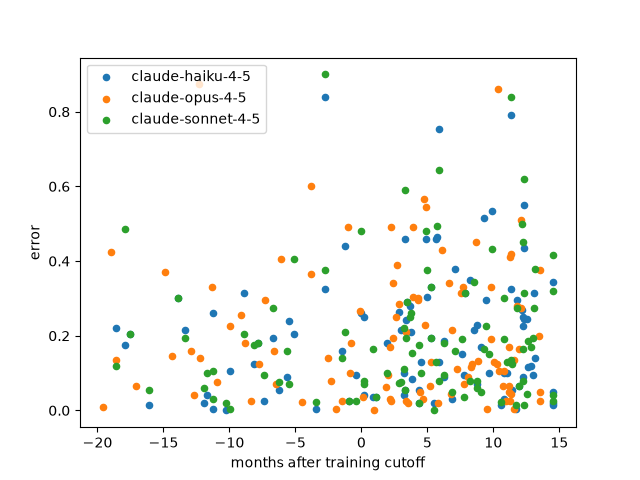

In [33]:
# one series per model so the legend says which model each point is
ax = None
for i, (model, points) in enumerate(trace_df.groupby("model")):
    ax = points.plot.scatter(
        x="time_diff", y="error", label=model, color=f"C{i}", ax=ax
    )
ax.set_xlabel("months after training cutoff")

In [34]:
# rows whose forecast could not be parsed have no error and would make the
# fit NaN
scored = trace_df.dropna(subset=["error"])


In [35]:
# ordinary least squares of error on months after the training cutoff, with
# a dummy per model (C(model); the first model alphabetically is the
# baseline) so the slope is estimated within model rather than across models
# that happen to sit at different distances from their cutoffs
fit = smf.ols("error ~ time_diff + C(model)", data=scored).fit()


In [36]:
fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  error   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                 -0.006
Method:                 Least Squares   F-statistic:                    0.4364
Date:                Tue, 27 Oct 2026   Prob (F-statistic):              0.727
Time:                        16:18:47   Log-Likelihood:                 94.147
No. Observations:                 300   AIC:                            -180.3
Df Residuals:                     296   BIC:                            -165.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=================================================================================================
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         0.1982      0.018     10.871      0.000       0.162       0.234
C(model)[T.claude-opus-4-5]       0.0021      0.025      0.082      0.935      -0.048       0.052
C(model)[T.claude-sonnet-4-5]    -0.0012      0.025     -0.049      0.961      -0.051       0.048
time_diff                         0.0014      0.001      1.142      0.255      -0.001       0.004
==============================================================================
Omnibus:                       81.843   Durbin-Watson:                   2.032
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              166.093
Skew:                           1.403   Prob(JB):                     8.58e-37
Kurtosis:                       5.327   Cond. No.                         30.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [37]:
# the same fit per model, slope in error per month with its p-value
by_model = scored.groupby("model").apply(
    lambda g: pd.Series(linregress(g["time_diff"], g["error"])._asdict()),
    include_groups=False,
)


In [38]:
by_model[["slope", "intercept", "rvalue", "pvalue"]]


,slope,intercept,rvalue,pvalue
model,,,,
claude-haiku-4-5,0.002538,0.194291,0.126754,0.208871
claude-opus-4-5,-0.000678,0.204929,-0.032400,0.748959
claude-sonnet-4-5,0.002221,0.194113,0.107364,0.287682


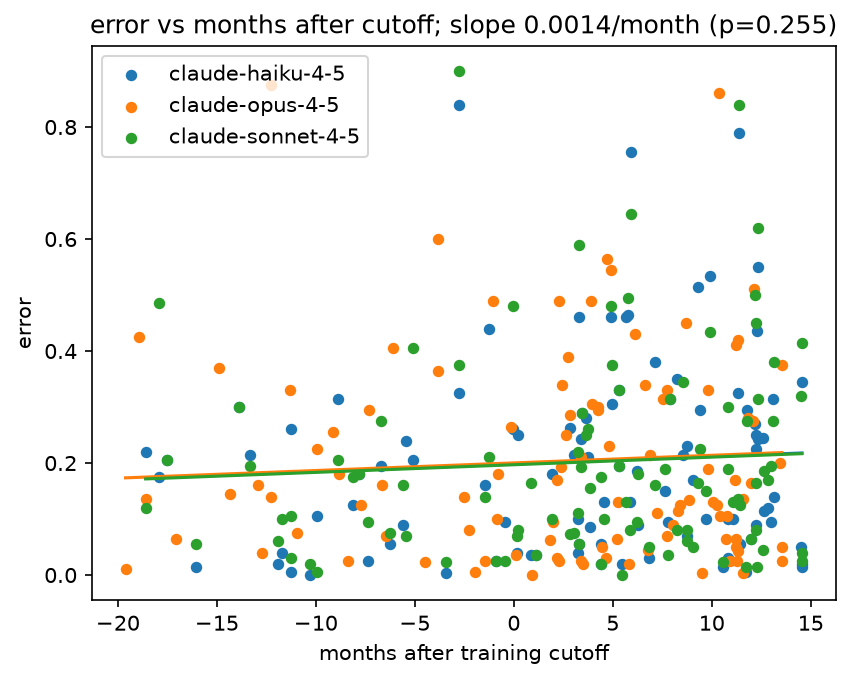

In [39]:
# the fitted line per model: common slope, model-specific intercept
for i, (model, points) in enumerate(scored.groupby("model")):
    x = points["time_diff"].sort_values()
    ax.plot(
        x,
        fit.predict(pd.DataFrame({"time_diff": x, "model": model})),
        color=f"C{i}",
    )
ax.set_title(
    f"error vs months after cutoff; slope {fit.params['time_diff']:.4f}/month (p={fit.pvalues['time_diff']:.3f})"
)
ax.figure
